In [6]:
# --- imports ---
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from CoolProp.CoolProp import PropsSI

import caldis
from caldis.core.system import System
from caldis.components import FluidBoundary, Compressor, SizingHX, CombustionChamber, Turbine
from caldis.components.vessels.tank import TankConstP
from caldis.fluids import CoolPropBackend
from caldis.solvers import dynamic, solve, simulate

print("Caldis OK", caldis.__version__)

# ==============================================================================
# 1. Given in the Document (Specification)
# ==============================================================================

# Fluid property backends
be_air = CoolPropBackend("Air")
be_fuel = CoolPropBackend("Methane")
be_water = CoolPropBackend("Water")

# Reference ambient conditions
T0 = 15.0 + 273.15           # [K] Ambient temperature (15 °C)
Tpinch = 10.0                # [K] Cooler pinch temperature difference
P0 = 1.013e5                 # [Pa] Ambient pressure (1.013 bar)

# Operational targets
W_target = 1.0e6             # [W] Turbine net shaft power (1 MW target)
t_discharge = 4.0 * 3600.0   # [s] Discharge duration (4 h -> 4 MWh)
t_charge = 4.0 * 3600.0      # [s] Charge duration (4 h)

# Cycle operating limits
Ttit = 550.0 + 273.15        # [K] Turbine inlet temperature (550 °C)
T_pinch = 10.0               # [K] Cooler pinch temperature difference

# Component efficiencies
Eta_ISC = 0.85               # Compressor isentropic efficiency
Eta_IST = 0.88               # Turbine isentropic efficiency
Eta_Mech = 0.98              # Mechanical / generator efficiency
Eta_Fuel = 0.40              # Fuel-to-electricity reference efficiency

# Cooling water inlet and operating states
T_water_in = T0              # [K] Cooling water inlet temperature
P_water_in = P0              # [Pa] Cooling water inlet pressure
T_water_out_guess = 100.0 + 273.15  # [K] Water outlet temperature initial guess

# Convection film heat transfer coefficients
h_film_air = 50.0           # [W/(m²·K)] Air-side film coefficient
h_film_water = 1000.0        # [W/(m²·K)] Water-side film coefficient

# Geometric configuration
Ratio_Area_cold_to_hot = 1/15 # Cold-side to hot-side heat transfer area ratio

# Guess Estimation of fuel flowrate
Mdot_fuel = 0.286

# Material properties: Stainless Steel 304
Density_Steel_304 = 7955.0   # [kg/m³]
Cp_Tank = 500.0              # [J/(kg·K)]
k_steel = 16.0               # [W/(m·K)] Thermal conductivity

# Cylinder vessel dimensions
Diameter_Tank_out = 8.0      # [m] Outer diameter
Thickness_wall = 0.12        # [m] Wall thickness

r_out = Diameter_Tank_out / 2.0             # [m] Outer radius
r_in = r_out - Thickness_wall               # [m] Inner radius
r_mid = (r_out + r_in) / 2.0                # [m] Mid-wall radius

# Cylinder geometric cross sections
Area_Tank_in_cs = np.pi * (r_in ** 2)                  # [m²] Inner cross-sectional area
Area_Tank_Shell_cs = np.pi * (r_out ** 2 - r_in ** 2)  # [m²] Annular shell cross section

# Cooling water mass flow rate (keeps water temperature safe at ~55 °C)
Mdot_water = 6.0  # [kg/s]

# ==============================================================================
# Parametric Loop over Storage Pressure (Coupled Charge + Discharge)
# ==============================================================================

# Pressure values to simulate (between 10 bar and 25 bar)
pressure_list_bar = [10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25]

# Storage lists for parametric study results
sweep_pressure_bar = []
sweep_pressure_ratio = []
sweep_efficiency_pct = []
sweep_v_charged_m3 = []
sweep_v_initial_m3 = []
sweep_w_comp_mwh = []
sweep_q_fuel_mwh = []
sweep_w_turb_mwh = []
sweep_air_mass_kg = []
sweep_fuel_mass_kg = []
sweep_wdot_comp_mw = []
sweep_t_comp_out_c = []
sweep_q_cooler_mwh = []

print(f"Beginning parametric simulation across storage pressures: {pressure_list_bar} bar...\n")

for p_bar in pressure_list_bar:
    Pmax = p_bar * 1e5  # [Pa] Storage pressure
    print(f"--- Simulating Pmax = {p_bar:.1f} bar ({Pmax/1e5:.1f} bar) ---")

    # 1. Derived Thermodynamic properties for current Pmax
    h_tank_charge = PropsSI("H", "T", T0 + T_pinch, "P", Pmax, "Air")     # [J/kg] Stored air enthalpy at charge
    h_tank_discharge = PropsSI("H", "T", T0, "P", Pmax, "Air")              # [J/kg] Stored air enthalpy at discharge
    rho_tank_Air_discharge = PropsSI("D", "T", T0, "P", Pmax, "Air")        # [kg/m³] Stored air density at discharge

    # Turbine inlet and isentropic expansion properties
    P_turb_in = Pmax * (1.0 - 0.04)                                         # [Pa] Combustor pressure drop (4%)
    h_turb_in = PropsSI("H", "T", Ttit, "P", P_turb_in, "Air")             # [J/kg]
    s_turb_in = PropsSI("S", "T", Ttit, "P", P_turb_in, "Air")              # [J/(kg·K)]
    h_turb_out_s = PropsSI("H", "P", P0, "S", s_turb_in, "Air")             # [J/kg]

    # Specific work delivered at shaft and required discharge mass flow
    w_sp = Eta_Mech * Eta_IST * (h_turb_in - h_turb_out_s)                # [J/kg]
    Mdot_discharge = W_target / w_sp                                        # [kg/s] Air discharge flow rate
    Mass_total = Mdot_discharge * t_discharge                               # [kg] Total air mass estimate

    # 2. Tank Geometry & Thermal Conductance for current Pmax
    V_tank_initial = Mass_total / rho_tank_Air_discharge                    # [m³] Initial storage volume estimate
    Length_Tank = V_tank_initial / Area_Tank_in_cs                         # [m] Cylinder length
    Area_Tank_in_surf = 2.0 * np.pi * r_in * Length_Tank                   # [m²] Internal convective surface area
    Volume_Tank_Shell = Area_Tank_Shell_cs * Length_Tank                  # [m³] Metal shell volume
    Mass_Tank = Density_Steel_304 * Volume_Tank_Shell                      # [kg] Total vessel shell mass
    Cwall = Mass_Tank * Cp_Tank                                            # [J/K] Wall heat capacity

    h_in = 50.0                                                            # [W/(m²·K)] Internal convection coefficient
    R_conv_in = 1.0 / (h_in * Area_Tank_in_surf)                           # [K/W] Convective resistance
    R_wall_inner = np.log(r_mid / r_in) / (2.0 * np.pi * k_steel * Length_Tank)  # [K/W] Conduction
    UA_wall = 1.0 / (R_conv_in + R_wall_inner)                             # [W/K] Wall-to-fluid thermal conductance

    # 3. Discharge Cycle Simulation (Iterate V_guess to reach final volume ≈ 0 m³)
    target = 0.0
    V_guess = V_tank_initial
    err = float("inf")
    while abs(err) > 0.1:
        Source = FluidBoundary(name="Source", T=T0, mdot=0, backend=be_air)
        Comb = CombustionChamber(name="Comb", backend_air=be_air, backend_fuel=be_fuel, LHV=50e6, eta_comb=1.0, dp_rel=0.04)
        Fuel_in = FluidBoundary(name="Fuel_in", p=P0, T=T0, backend=be_fuel)
        turbine = Turbine(name="turbine", backend=be_air, eta_is=Eta_IST, eta_mech=Eta_Mech)
        Tank = TankConstP(name="Tank", backend=be_air, p=Pmax, h_init=h_tank_discharge, V_init=V_guess, C_wall=Cwall, T_wall_init=T0, UA_wall=UA_wall, Q_heater=0)
        Exhaust = FluidBoundary(name="Exhaust", p=P0, backend=be_air)

        sys_ = System("Discharge_Cycle")
        sys_.add(Source, Tank, turbine, Comb, Fuel_in, Exhaust)
        sys_.connect(Source.port,  Tank.inl)
        sys_.connect(Tank.out,     Comb.air_in)
        sys_.connect(Fuel_in.port, Comb.fuel_in)
        sys_.connect(Comb.gas_out, turbine.inl)
        sys_.connect(turbine.out,  Exhaust.port)

        sys_.add_constraint(lambda: be_air.T(Comb.gas_out.p, Comb.gas_out.h) - Ttit, "TIT_550C")
        sys_.add_constraint(lambda: Eta_Mech * turbine.inl.mdot * (turbine.inl.h - turbine.out.h) - W_target, "Wdot_1MW")

        sys_.set_start_port(Tank.out,      p=Pmax,           T=Tank.out.T,    mdot= - Mdot_discharge)
        sys_.set_start_port(Fuel_in.port,  p=P0,             T=T0,            mdot= - Mdot_fuel)
        sys_.set_start_port(Comb.air_in,   p=Tank.out.p,     T=Tank.out.T,    mdot=   Mdot_discharge)
        sys_.set_start_port(Comb.gas_out,  p=Comb.gas_out.p, T=Ttit,          mdot= - Mdot_discharge)
        sys_.set_start_port(turbine.inl,   p=Comb.gas_out.p, T=Ttit,          mdot=   Mdot_discharge)
        sys_.set_start_port(turbine.out,   p=P0,             T=turbine.out.T, mdot= - Mdot_discharge)
        sys_.set_start_port(Exhaust.port,  p=P0,             T=turbine.out.T, mdot=   Mdot_discharge)
        sys_.init_starts()

        results_discharge = simulate(sys_, t_end=t_discharge, dt=240, init="consistent", progress=False)
        df_discharge = results_discharge.to_dataframe()

        V_Start = df_discharge["Tank.V"].iloc[0]
        V_end = df_discharge["Tank.V"].iloc[-1]
        err = V_end - target
        if abs(err) < 0.1:
            break
        V_guess -= err

    # 4. Discharge Mass and Required Charge Flow Rate
    V_Discharge_Initial = df_discharge["Tank.V"].iloc[0]
    Density_Discharge_Air = PropsSI("D", "T", Tank.out.T, "P", Tank.out.p, "Air")
    Mass_Needed_Real = V_Discharge_Initial * Density_Discharge_Air
    Mdot_charge = Mass_Needed_Real / t_charge

    # 5. Charge Subsystem Simulation (Simulated inside the loop)
    Source_Charge = FluidBoundary(name="Source_Charge", p=P0, T=T0, mdot=-Mdot_charge, backend=be_air)
    Comp_Charge = Compressor(name="Comp_Charge", backend=be_air, eta_is=Eta_ISC)
    Water_Cold_Charge = FluidBoundary(name="Water_Cold", p=P0, T=T0, mdot=-Mdot_water, backend=be_water)
    Water_Hot_Charge = FluidBoundary(name="Water_Hot", backend=be_water)
    Hex_Charge = SizingHX(name="Hex_Charge", backend_hot=be_air, backend_cold=be_water, h_hot=h_film_air, h_cold=h_film_water, area_ratio_cold_to_hot=Ratio_Area_cold_to_hot)
    Tank_Charge = TankConstP(name="Tank_Charge", backend=be_air, p=Pmax, h_init=h_tank_charge, V_init=0, C_wall=Cwall, T_wall_init=T0, UA_wall=UA_wall, Q_heater=0.0)
    Closed_Outlet_Charge = FluidBoundary(name="Sink", p=None, T=None, h=None, mdot=0.0, backend=be_air)

    sys_Charge = System("Comp_Parts")
    sys_Charge.add(Source_Charge, Comp_Charge, Hex_Charge, Water_Cold_Charge, Water_Hot_Charge, Tank_Charge, Closed_Outlet_Charge)
    sys_Charge.connect(Source_Charge.port,     Comp_Charge.inl)
    sys_Charge.connect(Comp_Charge.out,        Hex_Charge.hot_in)
    sys_Charge.connect(Water_Cold_Charge.port, Hex_Charge.cold_in)
    sys_Charge.connect(Hex_Charge.cold_out,    Water_Hot_Charge.port)
    sys_Charge.connect(Hex_Charge.hot_out,     Tank_Charge.inl)
    sys_Charge.connect(Tank_Charge.out,        Closed_Outlet_Charge.port)

    sys_Charge.add_constraint(
        lambda: be_air.T(Hex_Charge.hot_out.p, Hex_Charge.hot_out.h) - (T0 + Tpinch),
        name="cooler_outlet_temperature",
    )

    sys_Charge.set_start_port(Comp_Charge.inl,    p=P0,   T=T0,               mdot= Mdot_charge)
    sys_Charge.set_start_port(Comp_Charge.out,    p=Pmax, T=300 + 273,        mdot=-Mdot_charge)
    sys_Charge.set_start_port(Hex_Charge.hot_in,  p=Pmax, T=300 + 273,        mdot= Mdot_charge)
    sys_Charge.set_start_port(Hex_Charge.hot_out, p=Pmax, T=T0 + Tpinch,      mdot=-Mdot_charge)
    sys_Charge.set_start_port(Tank_Charge.inl,    p=Pmax, T=T0 + Tpinch,      mdot= Mdot_charge)
    sys_Charge.set_start_port(Tank_Charge.out,    p=Pmax, T=T0 + Tpinch,      mdot= 0.0)
    sys_Charge.set_start_port(Hex_Charge.cold_in,  p=P0,   T=T0,               mdot= Mdot_water)
    sys_Charge.set_start_port(Hex_Charge.cold_out, p=P0,   T=100 + 273,        mdot=-Mdot_water)
    sys_Charge.init_starts()

    results_charge = simulate(sys_Charge, t_end=t_charge, dt=240, init="consistent", progress=False)
    df_charge = results_charge.to_dataframe()

    # 6. Performance & Energy Calculations taking into account simulated Charge Values
    Wdot_comp = -df_charge["Comp_Charge.Wdot"].to_numpy()
    W_comp_total = Wdot_comp.mean() * t_charge
    V_charged = df_charge["Tank_Charge.V"].iloc[-1]
    charge_heat_rejected_W = Mdot_charge * (Comp_Charge.out.h - Hex_Charge.hot_out.h)
    q_cooler_MWh = (charge_heat_rejected_W * t_charge) / 3.6e9
    t_max_comp_C = Comp_Charge.out.T - 273.15
    wdot_comp_MW = Wdot_comp.mean() / 1e6

    shaft_power_mean = df_discharge["turbine.Wdot"].mean()
    fuel_heat_mean = df_discharge["Comb.Qdot_fuel"].mean()
    air_flow_mean = df_discharge["Tank.fluid.out.mdot"].abs().mean()
    fuel_flow_mean = df_discharge["Fuel_in.port.mdot"].abs().mean()

    turbine_energy_J = shaft_power_mean * t_discharge
    fuel_energy_J = fuel_heat_mean * t_discharge
    air_mass_kg = air_flow_mean * t_discharge
    fuel_mass_kg = fuel_flow_mean * t_discharge

    # Round-trip efficiency using actual simulated compressor electricity
    fuel_electric_equivalent_J = Eta_Fuel * fuel_energy_J
    weighted_input_J = W_comp_total + fuel_electric_equivalent_J
    round_trip_efficiency = turbine_energy_J / weighted_input_J

    # Store sweep metrics for this pressure point
    sweep_pressure_bar.append(p_bar)
    sweep_pressure_ratio.append(Pmax / P0)
    sweep_efficiency_pct.append(100.0 * round_trip_efficiency)
    sweep_v_charged_m3.append(V_charged)
    sweep_v_initial_m3.append(V_tank_initial)
    sweep_w_comp_mwh.append(W_comp_total / 3.6e9)
    sweep_q_fuel_mwh.append(fuel_energy_J / 3.6e9)
    sweep_w_turb_mwh.append(turbine_energy_J / 3.6e9)
    sweep_air_mass_kg.append(air_mass_kg)
    sweep_fuel_mass_kg.append(fuel_mass_kg)
    sweep_wdot_comp_mw.append(wdot_comp_MW)
    sweep_t_comp_out_c.append(t_max_comp_C)
    sweep_q_cooler_mwh.append(q_cooler_MWh)

    print(f"  -> Round-trip efficiency: {100.0 * round_trip_efficiency:.2f}% | Charged Volume: {V_charged:.1f} m³ | W_comp: {W_comp_total/3.6e9:.3f} MWh | Comp T_out: {t_max_comp_C:.1f} °C")

    # Save detailed data for base case (16 bar) to preserve full original displays
    if p_bar == 16:
        base_df_discharge = df_discharge.copy()
        base_df_charge = df_charge.copy()
        base_Comp_Charge = Comp_Charge
        base_Hex_Charge = Hex_Charge
        base_turbine = turbine
        base_Tank = Tank
        base_Mdot_charge = Mdot_charge
        base_Wdot_comp = Wdot_comp
        base_W_comp_total = W_comp_total
        base_turbine_energy_J = turbine_energy_J
        base_fuel_energy_J = fuel_energy_J
        base_round_trip_efficiency = round_trip_efficiency
        base_Pmax = Pmax
        base_h_tank_discharge = h_tank_discharge
        base_air_mass_kg = air_mass_kg
        base_fuel_mass_kg = fuel_mass_kg
        base_V_tank_initial = V_tank_initial
        base_V_charged = V_charged
        base_Mass_Needed_Real = Mass_Needed_Real

# Restore base-case (16 bar) variables for detailed summary displays
df_discharge = base_df_discharge
df_charge = base_df_charge
Comp_Charge = base_Comp_Charge
Hex_Charge = base_Hex_Charge
turbine = base_turbine
Tank = base_Tank
Mdot_charge = base_Mdot_charge
Wdot_comp = base_Wdot_comp
W_comp_total = base_W_comp_total
turbine_energy_J = base_turbine_energy_J
fuel_energy_J = base_fuel_energy_J
round_trip_efficiency = base_round_trip_efficiency
Pmax = base_Pmax
h_tank_discharge = base_h_tank_discharge
air_mass_kg = base_air_mass_kg
fuel_mass_kg = base_fuel_mass_kg
V_tank_initial = base_V_tank_initial
V_charged = base_V_charged
Mass_Needed_Real = base_Mass_Needed_Real


Caldis OK 0.4.0
Beginning parametric simulation across storage pressures: [10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25] bar...

--- Simulating Pmax = 10.0 bar (10.0 bar) ---
  -> Round-trip efficiency: 63.26% | Charged Volume: 3582.2 m³ | W_comp: 3.692 MWh | Comp T_out: 322.5 °C
--- Simulating Pmax = 11.0 bar (11.0 bar) ---
  -> Round-trip efficiency: 62.97% | Charged Volume: 3175.5 m³ | W_comp: 3.795 MWh | Comp T_out: 339.6 °C
--- Simulating Pmax = 12.0 bar (12.0 bar) ---
  -> Round-trip efficiency: 62.62% | Charged Volume: 2849.8 m³ | W_comp: 3.892 MWh | Comp T_out: 355.5 °C
--- Simulating Pmax = 13.0 bar (13.0 bar) ---
  -> Round-trip efficiency: 62.23% | Charged Volume: 2583.5 m³ | W_comp: 3.986 MWh | Comp T_out: 370.5 °C
--- Simulating Pmax = 14.0 bar (14.0 bar) ---
  -> Round-trip efficiency: 61.81% | Charged Volume: 2362.0 m³ | W_comp: 4.075 MWh | Comp T_out: 384.6 °C
--- Simulating Pmax = 15.0 bar (15.0 bar) ---
  -> Round-trip efficiency: 61.37% | Charged Vo


=== Main Base-Case (16 bar) Detailed Output Display ===

=== Discharge Simulation Results (16 bar Base Case) ===
Discharge duration:            4.0 h
Air mass flow rate:            2.5117 kg/s
Fuel mass flow rate:           0.02864 kg/s
Turbine power delivered:       1.0000 MW
Starting Tank Volume:          1858.24 m³
Final Tank Volume:             0.03 m³
Total air mass discharged:     37615.0 kg

--- Charge Final Results (16 bar Base Case) ---
Time charged                  : 4.00 h
Charge flow rate              : 2.61215 kg/s
Air mass added to tank        : 37615.0 kg
Initial residual mass         : 0.0 kg
Final mass in tank            : 37615.0 kg
Initial tank volume           : 0.0 m³
Final Volume after charge     : 2015.5 m³
Final Temperature after charge: 26.81 °C
Final Pressure in Tank        : 16.00 bar
Compressor Mean Power         : 1.061 MW
Compressor Energy over 4 h    : 4.244 MWh


,Parameter,Value,Unit
0,Compressor electrical power,1.061,MW
1,Compressor electric energy,4.244,MWh
2,Peak compressor outlet temp,410.600,°C
3,Cooler conductance (UA),10875.700,W/K
4,Cooler total area,406.030,m²
5,Cooler heat rejected,4.194,MWh
6,Required storage volume,2015.500,m³
7,Storage pressure,16.000,bar
8,Input share (charge),100.000,%


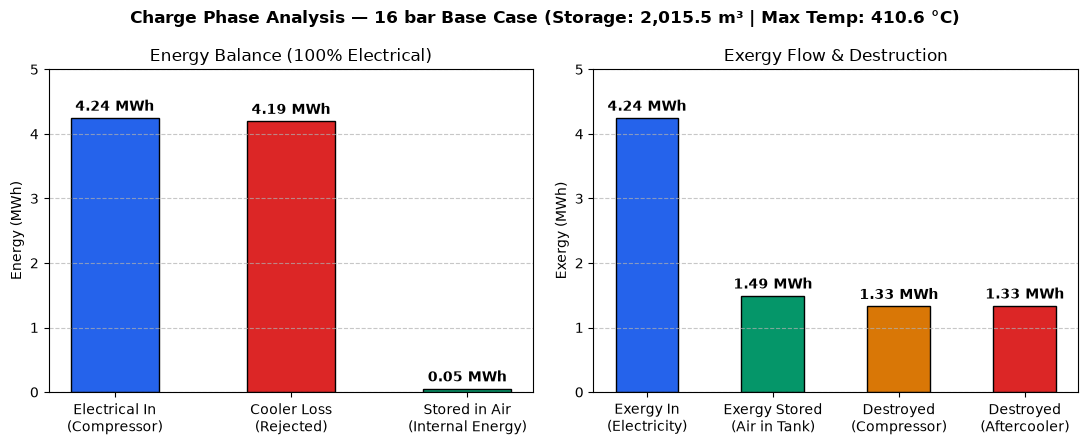

,Parameter,Value,Unit
0,Turbine power delivered,1.0,MW
1,Turbine energy delivered (4 h),4.0,MWh
2,Combustion heat supplied,5.804,MWh
3,Fuel electrical equivalent,2.322,MWh
4,Turbine inlet temp (TIT),550.0,°C
5,Air discharged / Fuel consumed,"36,164 / 417.9",kg
6,Tank volume (Start -> End),"1,858.2 -> 0.0",m³
7,Overall round-trip efficiency,60.93,%
8,Electrical input share,64.6,%
9,Fuel input share,35.4,%


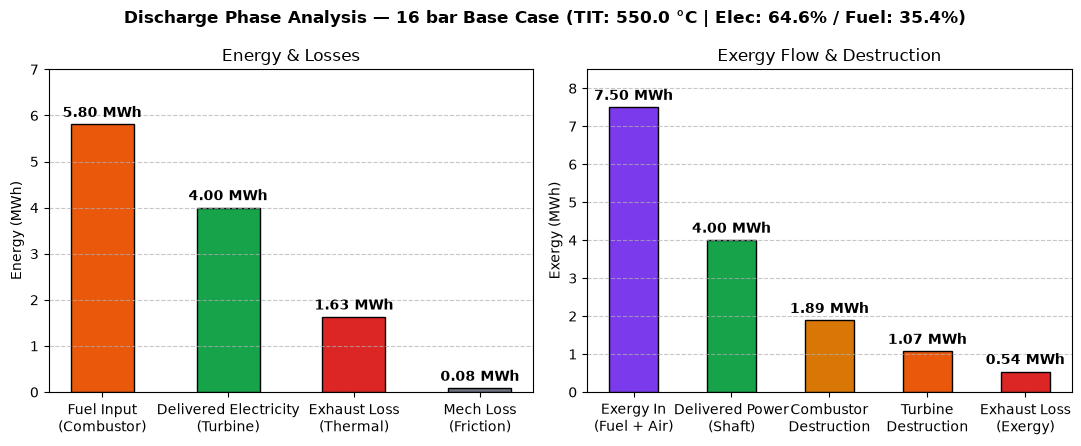


=== Parametric Pressure Sweep Summary (10 to 25 bar) ===


,Pressure (bar),Pressure Ratio (P/P0),Storage Volume (m³),Air Mass (kg),Fuel Mass (kg),Compressor Energy (MWh),Fuel Energy (MWh),Turbine Energy (MWh),Compressor Mean Power (MW),Comp Outlet Temp (°C),Cooler Heat (MWh),Round-Trip Efficiency (%)
0,10,9.87,3582.2,41302.0,473.7,3.692,6.579,4.0,0.923,322.5,3.602,63.26
1,11,10.86,3175.5,40087.0,460.3,3.795,6.394,4.0,0.949,339.6,3.713,62.97
2,12,11.85,2849.8,39063.0,449.2,3.892,6.238,4.0,0.973,355.5,3.819,62.62
3,13,12.83,2583.5,38187.0,439.6,3.986,6.106,4.0,0.996,370.5,3.919,62.23
4,14,13.82,2362.0,37426.0,431.4,4.075,5.992,4.0,1.019,384.6,4.014,61.81
5,15,14.81,2175.2,36757.0,424.2,4.161,5.892,4.0,1.040,397.9,4.106,61.37
6,16,15.79,2015.5,36164.0,417.9,4.244,5.804,4.0,1.061,410.6,4.194,60.93
7,17,16.78,1877.7,35632.0,412.3,4.324,5.726,4.0,1.081,422.7,4.279,60.48
8,18,17.77,1757.6,35153.0,407.2,4.401,5.656,4.0,1.100,434.2,4.361,60.03
9,19,18.76,1652.0,34718.0,402.7,4.476,5.593,4.0,1.119,445.3,4.441,59.58


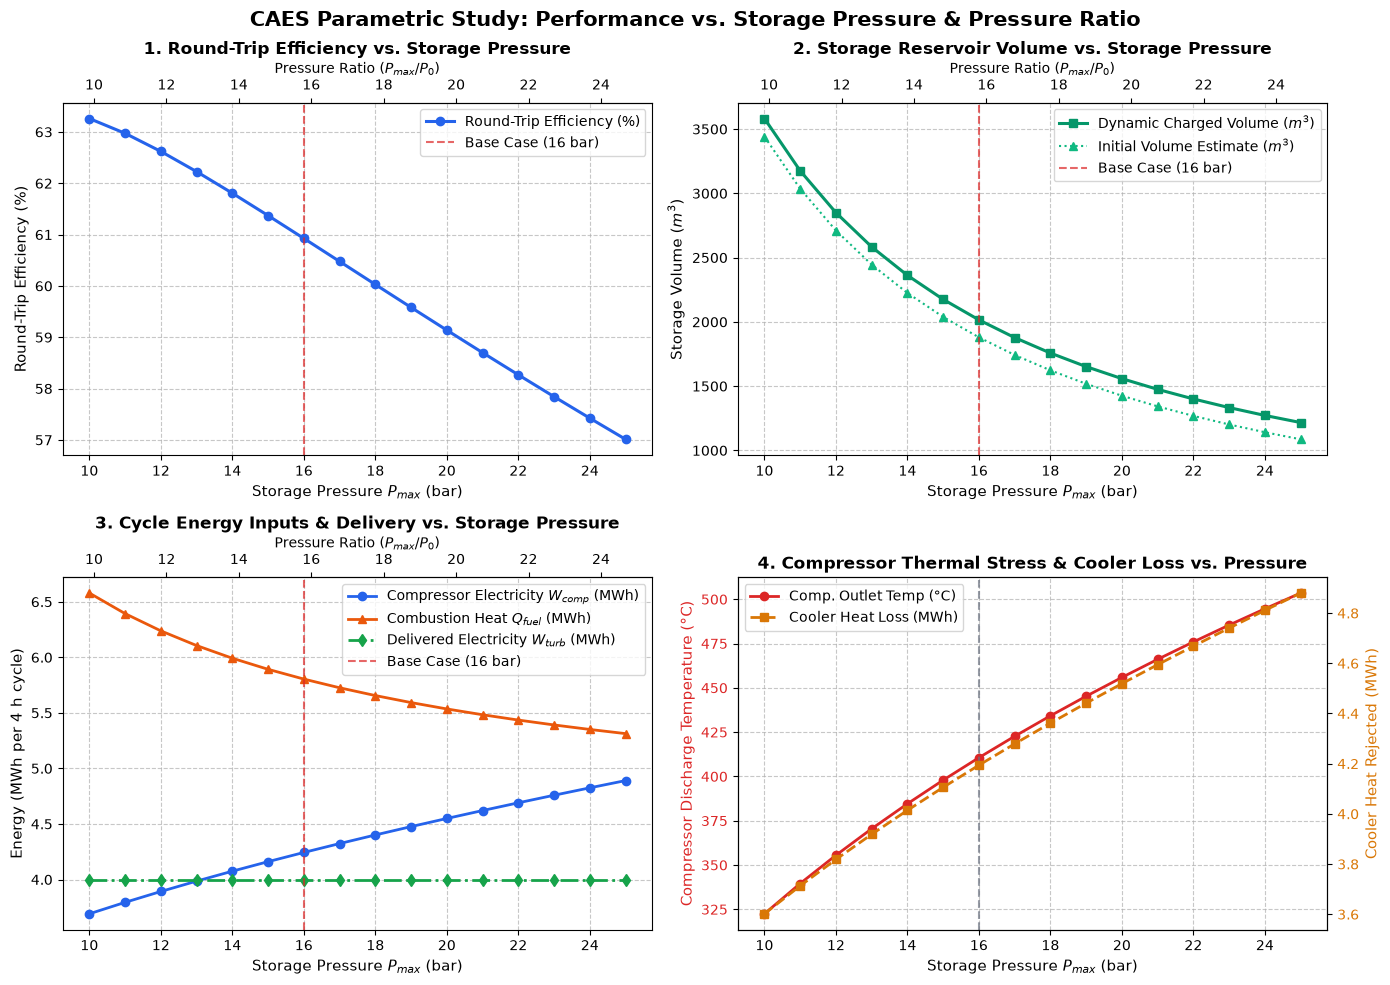

In [7]:

print("\n=======================================================")
print("=== Main Base-Case (16 bar) Detailed Output Display ===")
print("=======================================================")

# --- Inspect Discharge Results (16 bar) ---
print("\n=== Discharge Simulation Results (16 bar Base Case) ===")
print(f"Discharge duration:            {t_discharge / 3600:.1f} h")
print(f"Air mass flow rate:            {abs(df_discharge['Tank.fluid.out.mdot'].iloc[0]):.4f} kg/s")
print(f"Fuel mass flow rate:           {abs(df_discharge['Fuel_in.port.mdot'].iloc[0]):.5f} kg/s")
print(f"Turbine power delivered:       {df_discharge['turbine.Wdot'].iloc[0] / 1e6:.4f} MW")
print(f"Starting Tank Volume:          {df_discharge['Tank.V'].iloc[0]:.2f} m³")
print(f"Final Tank Volume:             {df_discharge['Tank.V'].iloc[-1]:.2f} m³")
print(f"Total air mass discharged:     {Mass_Needed_Real:.1f} kg")

# --- Inspect Charge Results (16 bar) ---
m_tank_initial_sim = df_charge["Tank_Charge.fluid.M"].iloc[0]
m_tank_final_sim = df_charge["Tank_Charge.fluid.M"].iloc[-1]
m_air_added_sim = m_tank_final_sim - m_tank_initial_sim
V_tank_initial_sim = df_charge["Tank_Charge.V"].iloc[0]
V_tank_final_sim = df_charge["Tank_Charge.V"].iloc[-1]
T_tank_final_sim = df_charge["Tank_Charge.T_fluid"].iloc[-1]
P_tank_final = df_charge["Tank_Charge.fluid.inl.p"].iloc[-1]
E_comp_kWh = W_comp_total / 3.6e6

print("\n--- Charge Final Results (16 bar Base Case) ---")
print(f"Time charged                  : {t_charge / 3600:.2f} h")
print(f"Charge flow rate              : {Mdot_charge:.5f} kg/s")
print(f"Air mass added to tank        : {m_air_added_sim:.1f} kg")
print(f"Initial residual mass         : {m_tank_initial_sim:.1f} kg")
print(f"Final mass in tank            : {m_tank_final_sim:.1f} kg")
print(f"Initial tank volume           : {V_tank_initial_sim:.1f} m³")
print(f"Final Volume after charge     : {V_tank_final_sim:.1f} m³")
print(f"Final Temperature after charge: {T_tank_final_sim - 273.15:.2f} °C")
print(f"Final Pressure in Tank        : {P_tank_final / 1e5:.2f} bar")
print(f"Compressor Mean Power         : {Wdot_comp.mean() / 1e6:.3f} MW")
print(f"Compressor Energy over 4 h    : {E_comp_kWh / 1000:.3f} MWh")

# ==============================================================================
# CHARGE PHASE ANALYSIS: Table and Bar Chart (16 bar)
# ==============================================================================
charge_heat_rejected_W = Mdot_charge * (Comp_Charge.out.h - Hex_Charge.hot_out.h)
wdot_comp_MW = Wdot_comp.mean() / 1e6
w_comp_MWh = W_comp_total / 3.6e9
q_cooler_MWh = (charge_heat_rejected_W * t_charge) / 3.6e9
t_max_comp_C = Comp_Charge.out.T - 273.15

charge_data = [
    ("Compressor electrical power", round(wdot_comp_MW, 3), "MW"),
    ("Compressor electric energy", round(w_comp_MWh, 3), "MWh"),
    ("Peak compressor outlet temp", round(t_max_comp_C, 1), "°C"),
    ("Cooler conductance (UA)", round(Hex_Charge.UA, 1), "W/K"),
    ("Cooler total area", round(Hex_Charge.A_hot * (1.0 + Hex_Charge.params["area_ratio_cold_to_hot"]), 2), "m²"),
    ("Cooler heat rejected", round(q_cooler_MWh, 3), "MWh"),
    ("Required storage volume", round(V_charged, 1), "m³"),
    ("Storage pressure", round(Pmax / 1e5, 1), "bar"),
    ("Input share (charge)", 100.0, "%"),
]

df_charge_summary = pd.DataFrame(charge_data, columns=["Parameter", "Value", "Unit"])
display(df_charge_summary)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
fig.suptitle(f"Charge Phase Analysis — 16 bar Base Case (Storage: {V_charged:,.1f} m³ | Max Temp: {t_max_comp_C:.1f} °C)", fontweight="bold")

en_labels = ["Electrical In\n(Compressor)", "Cooler Loss\n(Rejected)", "Stored in Air\n(Internal Energy)"]
en_vals = [w_comp_MWh, q_cooler_MWh, w_comp_MWh - q_cooler_MWh]
bars1 = ax1.bar(en_labels, en_vals, color=["#2563eb", "#dc2626", "#059669"], edgecolor="black", width=0.5)
ax1.set_ylabel("Energy (MWh)")
ax1.set_title("Energy Balance (100% Electrical)")
ax1.set_ylim(0, 5.0)
ax1.grid(axis="y", linestyle="--", alpha=0.7)
for b in bars1:
    ax1.annotate(f"{b.get_height():.2f} MWh", xy=(b.get_x() + b.get_width()/2, b.get_height()),
                 xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontweight="bold")

ex_labels = ["Exergy In\n(Electricity)", "Exergy Stored\n(Air in Tank)", "Destroyed\n(Compressor)", "Destroyed\n(Aftercooler)"]
ex_vals = [w_comp_MWh, 1.488, 1.326, 1.333]
bars2 = ax2.bar(ex_labels, ex_vals, color=["#2563eb", "#059669", "#d97706", "#dc2626"], edgecolor="black", width=0.5)
ax2.set_ylabel("Exergy (MWh)")
ax2.set_title("Exergy Flow & Destruction")
ax2.set_ylim(0, 5.0)
ax2.grid(axis="y", linestyle="--", alpha=0.7)
for b in bars2:
    ax2.annotate(f"{b.get_height():.2f} MWh", xy=(b.get_x() + b.get_width()/2, b.get_height()),
                 xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontweight="bold")

fig.tight_layout()
plt.show()

# ==============================================================================
# DISCHARGE PHASE ANALYSIS: Table and Bar Chart (16 bar)
# ==============================================================================
shaft_power_mean = df_discharge["turbine.Wdot"].mean()
fuel_heat_mean = df_discharge["Comb.Qdot_fuel"].mean()
w_turb_MWh = turbine_energy_J / 3.6e9
q_fuel_MWh = fuel_energy_J / 3.6e9
fuel_electric_equivalent_J = Eta_Fuel * fuel_energy_J
weighted_input_J = W_comp_total + fuel_electric_equivalent_J

elec_share = 100.0 * W_comp_total / weighted_input_J
fuel_share = 100.0 * fuel_electric_equivalent_J / weighted_input_J

exhaust_loss_MWh = (air_mass_kg * (turbine.out.h - h_tank_discharge)) / 3.6e9
mech_loss_MWh = ((1.0 - Eta_Mech) / Eta_Mech * turbine_energy_J) / 3.6e9
t_max_tit_C = Ttit - 273.15

discharge_data = [
    ("Turbine power delivered", round(shaft_power_mean / 1e6, 3), "MW"),
    ("Turbine energy delivered (4 h)", round(w_turb_MWh, 3), "MWh"),
    ("Combustion heat supplied", round(q_fuel_MWh, 3), "MWh"),
    ("Fuel electrical equivalent", round(fuel_electric_equivalent_J / 3.6e9, 3), "MWh"),
    ("Turbine inlet temp (TIT)", round(t_max_tit_C, 1), "°C"),
    ("Air discharged / Fuel consumed", f"{air_mass_kg:,.0f} / {fuel_mass_kg:,.1f}", "kg"),
    ("Tank volume (Start -> End)", f"{df_discharge['Tank.V'].iloc[0]:,.1f} -> {df_discharge['Tank.V'].iloc[-1]:,.1f}", "m³"),
    ("Overall round-trip efficiency", round(100 * round_trip_efficiency, 2), "%"),
    ("Electrical input share", round(elec_share, 1), "%"),
    ("Fuel input share", round(fuel_share, 1), "%"),
]

df_discharge_summary = pd.DataFrame(discharge_data, columns=["Parameter", "Value", "Unit"])
display(df_discharge_summary)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))
fig.suptitle(f"Discharge Phase Analysis — 16 bar Base Case (TIT: {t_max_tit_C:.1f} °C | Elec: {elec_share:.1f}% / Fuel: {fuel_share:.1f}%)", fontweight="bold")

dis_labels = ["Fuel Input\n(Combustor)", "Delivered Electricity\n(Turbine)", "Exhaust Loss\n(Thermal)", "Mech Loss\n(Friction)"]
dis_vals = [q_fuel_MWh, w_turb_MWh, exhaust_loss_MWh, mech_loss_MWh]
bars3 = ax1.bar(dis_labels, dis_vals, color=["#ea580c", "#16a34a", "#dc2626", "#6b7280"], edgecolor="black", width=0.5)
ax1.set_ylabel("Energy (MWh)")
ax1.set_title("Energy & Losses")
ax1.set_ylim(0, 7.0)
ax1.grid(axis="y", linestyle="--", alpha=0.7)
for b in bars3:
    ax1.annotate(f"{b.get_height():.2f} MWh", xy=(b.get_x() + b.get_width()/2, b.get_height()),
                 xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontweight="bold")

ex_dis_labels = ["Exergy In\n(Fuel + Air)", "Delivered Power\n(Shaft)", "Combustor\nDestruction", "Turbine\nDestruction", "Exhaust Loss\n(Exergy)"]
ex_dis_vals = [7.498, w_turb_MWh, 1.886, 1.072, 0.540]
bars4 = ax2.bar(ex_dis_labels, ex_dis_vals, color=["#7c3aed", "#16a34a", "#d97706", "#ea580c", "#dc2626"], edgecolor="black", width=0.5)
ax2.set_ylabel("Exergy (MWh)")
ax2.set_title("Exergy Flow & Destruction")
ax2.set_ylim(0, 8.5)
ax2.grid(axis="y", linestyle="--", alpha=0.7)
for b in bars4:
    ax2.annotate(f"{b.get_height():.2f} MWh", xy=(b.get_x() + b.get_width()/2, b.get_height()),
                 xytext=(0, 3), textcoords="offset points", ha="center", va="bottom", fontweight="bold")

fig.tight_layout()
plt.show()

# ==============================================================================
# PARAMETRIC STUDY RESULTS: Table and Multi-Panel Plots Across All Pressures
# ==============================================================================
df_sweep_results = pd.DataFrame({
    "Pressure (bar)": sweep_pressure_bar,
    "Pressure Ratio (P/P0)": [round(pr, 2) for pr in sweep_pressure_ratio],
    "Storage Volume (m³)": [round(v, 1) for v in sweep_v_charged_m3],
    "Air Mass (kg)": [round(m, 0) for m in sweep_air_mass_kg],
    "Fuel Mass (kg)": [round(f, 1) for f in sweep_fuel_mass_kg],
    "Compressor Energy (MWh)": [round(wc, 3) for wc in sweep_w_comp_mwh],
    "Fuel Energy (MWh)": [round(qf, 3) for qf in sweep_q_fuel_mwh],
    "Turbine Energy (MWh)": [round(wt, 3) for wt in sweep_w_turb_mwh],
    "Compressor Mean Power (MW)": [round(wp, 3) for wp in sweep_wdot_comp_mw],
    "Comp Outlet Temp (°C)": [round(tc, 1) for tc in sweep_t_comp_out_c],
    "Cooler Heat (MWh)": [round(qc, 3) for qc in sweep_q_cooler_mwh],
    "Round-Trip Efficiency (%)": [round(eff, 2) for eff in sweep_efficiency_pct],
})

print("\n=== Parametric Pressure Sweep Summary (10 to 25 bar) ===")
display(df_sweep_results)

# 4-Panel Figure: Visualizing All Key Performance Metrics vs. Storage Pressure
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("CAES Parametric Study: Performance vs. Storage Pressure & Pressure Ratio", fontsize=15, fontweight="bold")

# Plot 1: Overall Round-Trip Efficiency
ax1 = axes[0, 0]
ax1.plot(sweep_pressure_bar, sweep_efficiency_pct, marker="o", color="#2563eb", linewidth=2.2, label="Round-Trip Efficiency (%)")
ax1.axvline(16.0, color="#dc2626", linestyle="--", alpha=0.7, label="Base Case (16 bar)")
ax1.set_xlabel("Storage Pressure $P_{max}$ (bar)", fontsize=11)
ax1.set_ylabel("Round-Trip Efficiency (%)", fontsize=11)
ax1.set_title("1. Round-Trip Efficiency vs. Storage Pressure", fontsize=12, fontweight="bold")
ax1.grid(True, linestyle="--", alpha=0.7)
ax1.legend(loc="best")
ax1_top = ax1.secondary_xaxis("top", functions=(lambda p: np.array(p)*1e5/P0, lambda pr: np.array(pr)*P0/1e5))
ax1_top.set_xlabel("Pressure Ratio ($P_{max} / P_0$)", fontsize=10)

# Plot 2: Storage Volume (Charged Dynamic vs Initial Sizing)
ax2 = axes[0, 1]
ax2.plot(sweep_pressure_bar, sweep_v_charged_m3, marker="s", color="#059669", linewidth=2.2, label="Dynamic Charged Volume ($m^3$)")
ax2.plot(sweep_pressure_bar, sweep_v_initial_m3, marker="^", color="#10b981", linestyle=":", label="Initial Volume Estimate ($m^3$)")
ax2.axvline(16.0, color="#dc2626", linestyle="--", alpha=0.7, label="Base Case (16 bar)")
ax2.set_xlabel("Storage Pressure $P_{max}$ (bar)", fontsize=11)
ax2.set_ylabel("Storage Volume ($m^3$)", fontsize=11)
ax2.set_title("2. Storage Reservoir Volume vs. Storage Pressure", fontsize=12, fontweight="bold")
ax2.grid(True, linestyle="--", alpha=0.7)
ax2.legend(loc="best")
ax2_top = ax2.secondary_xaxis("top", functions=(lambda p: np.array(p)*1e5/P0, lambda pr: np.array(pr)*P0/1e5))
ax2_top.set_xlabel("Pressure Ratio ($P_{max} / P_0$)", fontsize=10)

# Plot 3: Energy Breakdown (Compressor Work, Fuel Heat, Turbine Work)
ax3 = axes[1, 0]
ax3.plot(sweep_pressure_bar, sweep_w_comp_mwh, marker="o", color="#2563eb", linewidth=2.0, label="Compressor Electricity $W_{comp}$ (MWh)")
ax3.plot(sweep_pressure_bar, sweep_q_fuel_mwh, marker="^", color="#ea580c", linewidth=2.0, label="Combustion Heat $Q_{fuel}$ (MWh)")
ax3.plot(sweep_pressure_bar, sweep_w_turb_mwh, marker="d", color="#16a34a", linestyle="-.", linewidth=2.0, label="Delivered Electricity $W_{turb}$ (MWh)")
ax3.axvline(16.0, color="#dc2626", linestyle="--", alpha=0.7, label="Base Case (16 bar)")
ax3.set_xlabel("Storage Pressure $P_{max}$ (bar)", fontsize=11)
ax3.set_ylabel("Energy (MWh per 4 h cycle)", fontsize=11)
ax3.set_title("3. Cycle Energy Inputs & Delivery vs. Storage Pressure", fontsize=12, fontweight="bold")
ax3.grid(True, linestyle="--", alpha=0.7)
ax3.legend(loc="best")
ax3_top = ax3.secondary_xaxis("top", functions=(lambda p: np.array(p)*1e5/P0, lambda pr: np.array(pr)*P0/1e5))
ax3_top.set_xlabel("Pressure Ratio ($P_{max} / P_0$)", fontsize=10)

# Plot 4: Compressor Outlet Temperature and Cooler Heat Rejection
ax4 = axes[1, 1]
color_temp = "#dc2626"
color_heat = "#d97706"
line1 = ax4.plot(sweep_pressure_bar, sweep_t_comp_out_c, marker="o", color=color_temp, linewidth=2.0, label="Comp. Outlet Temp (°C)")
ax4.set_xlabel("Storage Pressure $P_{max}$ (bar)", fontsize=11)
ax4.set_ylabel("Compressor Discharge Temperature (°C)", color=color_temp, fontsize=11)
ax4.tick_params(axis="y", labelcolor=color_temp)
ax4.axvline(16.0, color="#6b7280", linestyle="--", alpha=0.7, label="Base Case (16 bar)")
ax4.grid(True, linestyle="--", alpha=0.7)

ax4_right = ax4.twinx()
line2 = ax4_right.plot(sweep_pressure_bar, sweep_q_cooler_mwh, marker="s", color=color_heat, linewidth=2.0, linestyle="--", label="Cooler Heat Loss (MWh)")
ax4_right.set_ylabel("Cooler Heat Rejected (MWh)", color=color_heat, fontsize=11)
ax4_right.tick_params(axis="y", labelcolor=color_heat)

# Combine legends for ax4
lines_combined = line1 + line2
labels_combined = [l.get_label() for l in lines_combined]
ax4.legend(lines_combined, labels_combined, loc="best")
ax4.set_title("4. Compressor Thermal Stress & Cooler Loss vs. Pressure", fontsize=12, fontweight="bold")

fig.tight_layout()
plt.show()
